# 01 - EDA on 2019 AVSspoof

**Goal:** Find out if there are any signals in the data that distinguish a real from a fake voice.

*Note:* We are only using the 2019 LA (Logical Assess) **train** and **dev** sets here for EDA. The 2019 **eval** and all of the 2021 data will be untouched until the final test.

## Contents

1. Setup
2. Data Loading
3. Investigating Class Imbalance
4. Examining the Different Fake-making Methods
5. Investigating Audio Clips
6. Examining Silence
7. Sample Audio Clips
8. Investigating Clip Length
9. Choosing the Clip Length
10. Summary

## Setup

Loads the libraries and the project's shared code, and defines a few labels used throughout.

- **`autoreload`**: if you edit a file in `src/` (such as `data.py`), the notebook picks up the change without restarting.
- **`src/config.py`**: audio settings (`CLIP_SECONDS` is the fixed clip length).
- **`src/data.py`**: `load_la_2019` reads a label file and returns a table with one row per clip.
- **`REAL` / `FAKE`**: the label numbers used in every table (0 = real, 1 = fake). `NAMES` and `COLORS` give each label a readable name and a plot color, so real is always blue and fake is always red.

In [44]:
# Re-import edited files from src/ automatically, and show plots inside the notebook
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Let the notebook import our shared code from src/
import sys
sys.path.insert(0, "../src")

# Tables, numbers and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reading, measuring and displaying audio
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

# Score for how well one measurement separates real from fake (section 5)
from sklearn.metrics import roc_auc_score

# Project code: fixed clip length and the label-file loader
from config import CLIP_SECONDS
from data import load_la_2019

# Label numbers, plus a readable name and plot color for each
REAL, FAKE = 0, 1
NAMES = {REAL: "real", FAKE: "fake"}
COLORS = {REAL: "tab:blue", FAKE: "tab:red"}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data Loading

Each row is one audio clip: speaker, file name, fake-making method (`-` for real), and label (0 = real, 1 = fake).

In [45]:
train = load_la_2019("train")
dev = load_la_2019("dev")
train.head()

,speaker,file,system,label,path
0,LA_0079,LA_T_1138215,-,0,/Users/admin/Documents/CS467/VishingDetector/d...
1,LA_0079,LA_T_1271820,-,0,/Users/admin/Documents/CS467/VishingDetector/d...
2,LA_0079,LA_T_1272637,-,0,/Users/admin/Documents/CS467/VishingDetector/d...
3,LA_0079,LA_T_1276960,-,0,/Users/admin/Documents/CS467/VishingDetector/d...
4,LA_0079,LA_T_1341447,-,0,/Users/admin/Documents/CS467/VishingDetector/d...


In [46]:
for name, df in [("train", train), ("dev", dev)]:
    counts = df["label"].value_counts()
    print(f"{name}: {len(df):,} clips | real {counts[REAL]:,} | fake {counts[FAKE]:,} | speakers {df['speaker'].nunique()}")

train: 25,380 clips | real 2,580 | fake 22,800 | speakers 20
dev: 24,844 clips | real 2,548 | fake 22,296 | speakers 20


## Investigating Class Imbalance

Fakes far outnumber real clips. Because of this we will need to weight real clips more during training.

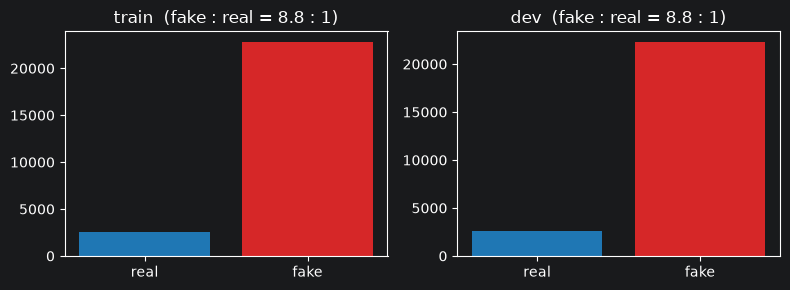

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
for a, (name, df) in zip(ax, [("train", train), ("dev", dev)]):
    counts = df["label"].value_counts().sort_index()
    a.bar([NAMES[i] for i in counts.index], counts.values, color=[COLORS[i] for i in counts.index])
    a.set_title(f"{name}  (fake : real = {counts[FAKE] / counts[REAL]:.1f} : 1)")
plt.tight_layout()

## Examining the Different Fake-making Methods

The train and dev sets use the same six methods (A01 to A06). The final test set adds new ones, so we won't see unseen methods until then.

In [48]:
methods = pd.concat([
    train[train.label == FAKE]["system"].value_counts().rename("train"),
    dev[dev.label == FAKE]["system"].value_counts().rename("dev"),
], axis=1).sort_index()
methods

,train,dev
system,,
A01,3800,3716
A02,3800,3716
A03,3800,3716
A04,3800,3716
A05,3800,3716
A06,3800,3716


## Investigating Audio Clips

For 300 random clips per label from train, examine the following attributes: length, loudness, and silence at the start and end of each clip.

We're measuring silence with `librosa.effects.trim`, which cuts everything more than 30 dB quieter than the loudest part.

In [49]:
def clip_stats(path):
    y, sr = sf.read(path)
    _, (start, end) = librosa.effects.trim(y, top_db=30)
    rms = np.sqrt(np.mean(y ** 2))
    return {
        "seconds": len(y) / sr,
        "loudness_db": 20 * np.log10(rms + 1e-10),
        "lead_silence": start / sr,
        "trail_silence": (len(y) - end) / sr,
    }

sample = pd.concat([
    train[train.label == REAL].sample(300, random_state=0),
    train[train.label == FAKE].sample(300, random_state=0),
]).reset_index(drop=True)
stats = pd.DataFrame([clip_stats(p) for p in sample["path"]])
sample = pd.concat([sample, stats], axis=1)
sample.groupby("label")[list(stats.columns)].describe().T.round(2)

label                     0       1
seconds       count  300.00  300.00
              mean     3.41    3.38
              std      0.95    1.49
              min      1.45    0.94
              25%      2.73    2.30
              50%      3.24    3.07
              75%      3.98    4.12
              max      7.81   10.83
loudness_db   count  300.00  300.00
              mean   -18.73  -18.29
              std      1.94    2.20
              min    -24.62  -24.02
              25%    -20.09  -19.61
              50%    -18.59  -18.31
              75%    -17.36  -17.04
              max    -13.86  -11.94
lead_silence  count  300.00  300.00
              mean     1.02    0.56
              std      0.35    0.50
              min      0.00    0.00
              25%      0.80    0.10
              50%      0.96    0.38
              75%      1.18    0.99
              max      2.62    2.27
trail_silence count  300.00  300.00
              mean     0.39    0.32
              std      0.40    0.26
              min      0.00    0.00
              25%      0.16    0.17
              50%      0.30    0.30
              75%      0.50    0.40
              max      3.23    1.80

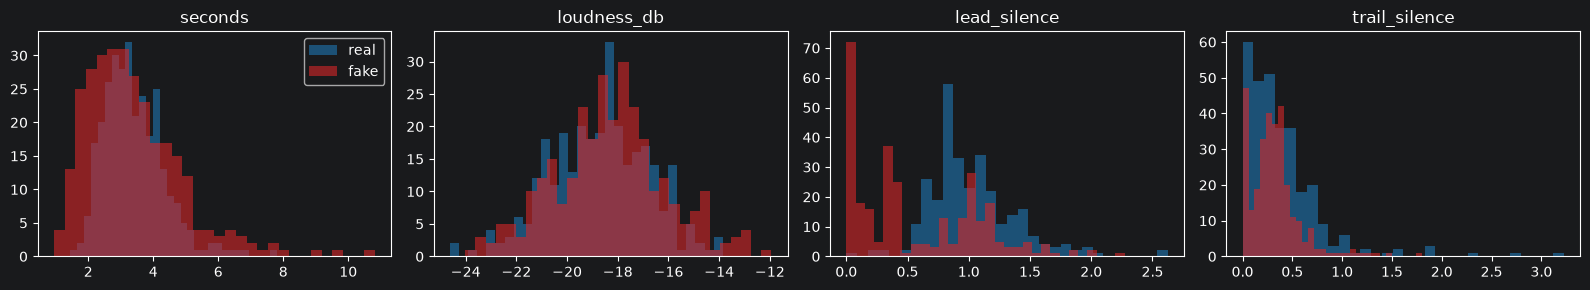

In [50]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, col in zip(axes, stats.columns):
    for label in (REAL, FAKE):
        ax.hist(sample[sample.label == label][col], bins=30, alpha=0.6,
                color=COLORS[label], label=NAMES[label])
    ax.set_title(col)
axes[0].legend()
plt.tight_layout()

## Examining Silence

If real and fake clips differ in how much silence they have, a model could score well by listening to the silence instead of the voice.

Below, each measurement is used **on its own** to separate real from fake. The score is 0.5 if it tells us nothing and 1.0 if it separates them perfectly.

In [51]:
rows = []
for col in stats.columns:
    auc = roc_auc_score(sample["label"], sample[col])
    rows.append({"measurement": col, "separation score": round(max(auc, 1 - auc), 3)})
pd.DataFrame(rows)

,measurement,separation score
0,seconds,0.547
1,loudness_db,0.554
2,lead_silence,0.752
3,trail_silence,0.533


## Sample Audio Clips

We're going to look and listen at five random real and five random fake clips from the train set. The spectrogram shows how much energy there is at each pitch (vertical) over time (horizontal).

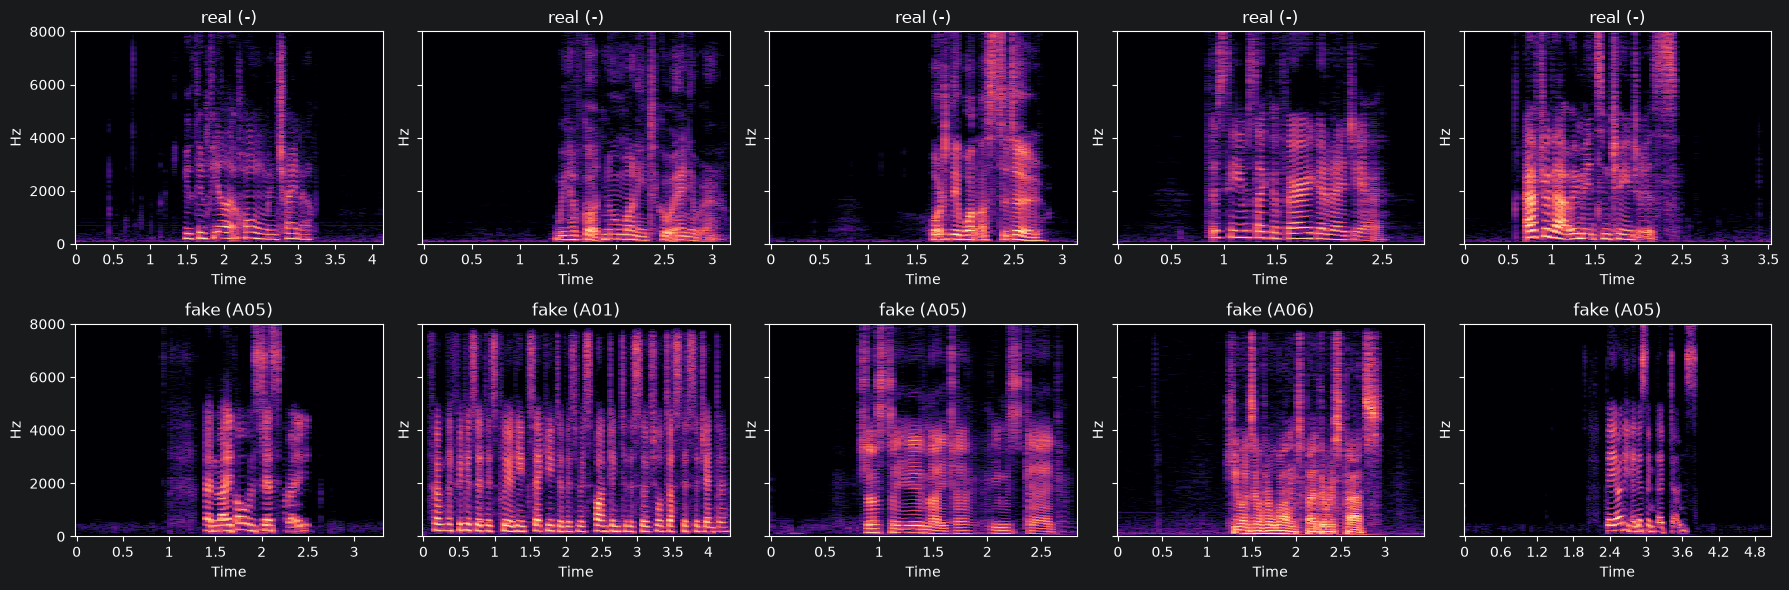

In [52]:
picks = pd.concat([
    train[train.label == REAL].sample(5, random_state=1),
    train[train.label == FAKE].sample(5, random_state=1),
])

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=True)
for ax, (_, row) in zip(axes.ravel(), picks.iterrows()):
    y, sr = sf.read(row["path"])
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(f"{NAMES[row['label']]} ({row['system']})")
plt.tight_layout()

In [53]:
# Decode the FLAC file and let Audio re-encode it as WAV, which every browser can play
for _, row in picks.iterrows():
    print(f"{NAMES[row['label']]} ({row['system']}): {row['file']}")
    y, sr = sf.read(row["path"])
    display(Audio(y, rate=sr))

real (-): LA_T_4928920


real (-): LA_T_2582808


real (-): LA_T_8125498


real (-): LA_T_4657133


real (-): LA_T_8002835


fake (A05): LA_T_7646072


fake (A01): LA_T_1775438


fake (A05): LA_T_6918234


fake (A06): LA_T_3498553


fake (A05): LA_T_5531480


**Observations:**

- Fake clips tend to show more regular, repeating vertical stripes and blockier bands of energy, depending on the method. Real clips look blotchier and more irregular.
- By ear, real and fake clips are easy to tell apart.

## Investigating Clip Length

During feature extraction, every clip will be cut or repeated to one fixed length (`CLIP_SECONDS`) so all features are the same size. The numbers below show how many clips that will affect.

In [54]:
print(sample["seconds"].describe().round(2))
print()
for label in (REAL, FAKE):
    s = sample[sample.label == label]["seconds"]
    print(f"{NAMES[label]}: {(s < CLIP_SECONDS).mean():.0%} shorter than {CLIP_SECONDS} s, "
          f"{(s > CLIP_SECONDS).mean():.0%} longer")

count    600.00
mean       3.40
std        1.25
min        0.94
25%        2.55
50%        3.20
75%        4.05
max       10.83
Name: seconds, dtype: float64

real: 75% shorter than 4 s, 25% longer
fake: 72% shorter than 4 s, 28% longer


## Choosing the Clip Length

EDA can't prove one length is best, but it can show what each choice costs. A shorter length cuts off more speech. A longer length repeats more short clips, and repeated audio isn't real speech.

Three checks, all on train:

1. Lengths of **all** clips, and whether length alone separates real from fake.
2. Length of the **speech only**, with the leading and trailing silence removed. This is the length that matters if we trim silence.
3. For each candidate length, how many clips would be repeated or cut, and how much speech would be lost.

         count  mean   std   min   25%   50%   75%    max
label                                                    
real    2580.0  3.39  0.99  1.36  2.69  3.24  3.92  11.13
fake   22800.0  3.43  1.46  0.65  2.39  3.20  4.14  13.19

score of length alone separating real from fake: 0.521 (0.5 = no information)


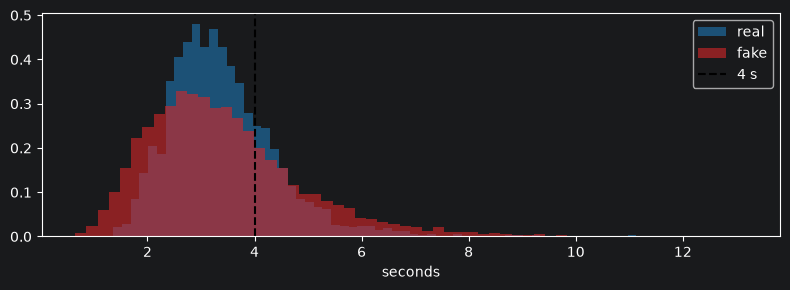

In [55]:
# Length of every train clip, read from the file header (no audio is loaded)
train["seconds"] = [sf.info(p).duration for p in train["path"]]

print(train.groupby("label")["seconds"].describe().round(2).rename(index=NAMES))

auc = roc_auc_score(train["label"], train["seconds"])
print(f"\nscore of length alone separating real from fake: {max(auc, 1 - auc):.3f} (0.5 = no information)")

fig, ax = plt.subplots(figsize=(8, 3))
for label in (REAL, FAKE):
    ax.hist(train[train.label == label]["seconds"], bins=60, alpha=0.6, density=True,
            color=COLORS[label], label=NAMES[label])
ax.axvline(CLIP_SECONDS, color="black", linestyle="--", label=f"{CLIP_SECONDS} s")
ax.set_xlabel("seconds")
ax.legend()
plt.tight_layout()

In [56]:
# Speech-only length for the 600-clip sample: total length minus the silence at both ends
sample["speech_seconds"] = sample["seconds"] - sample["lead_silence"] - sample["trail_silence"]
print(sample.groupby("label")["speech_seconds"].describe().round(2).rename(index=NAMES))

       count  mean   std   min   25%   50%   75%    max
label                                                  
real   300.0  2.00  0.73  0.58  1.44  1.84  2.46   5.06
fake   300.0  2.49  1.47  0.51  1.54  2.05  2.95  10.43


In [57]:
# What each candidate length would do to the clips.
# repeated / cut: share of all train clips shorter / longer than the length.
# speech lost: share of a clip's speech that falls past the cut (sample only, silence trimmed).
rows = []
for length in [2, 3, 4, 5, 6]:
    row = {"length (s)": length}
    for label in (REAL, FAKE):
        secs = train[train.label == label]["seconds"]
        speech = sample[sample.label == label]["speech_seconds"]
        row[f"{NAMES[label]} repeated"] = (secs < length).mean()
        row[f"{NAMES[label]} cut"] = (secs > length).mean()
        row[f"{NAMES[label]} speech lost"] = (np.maximum(speech - length, 0) / speech).mean()
    rows.append(row)

pd.DataFrame(rows).set_index("length (s)").round(2)

,real repeated,real cut,real speech lost,fake repeated,fake cut,fake speech lost
length (s),,,,,,
2,0.04,0.96,0.10,0.14,0.86,0.17
3,0.38,0.62,0.01,0.44,0.56,0.07
4,0.77,0.23,0.00,0.72,0.28,0.03
5,0.94,0.06,0.00,0.87,0.13,0.01
6,0.98,0.02,0.00,0.94,0.06,0.01


It *seems* like `3s` has the best trade-off. Under 3s, 38% of real and 44% of fake clips are repeated, and 1% of real and 7% of fake speech is lost. At 2s, 10% of real and 17% of fake speech is lost.

## Summary

| Question | Finding | What we do about it |
|---|---|---|
| How big is the data? | Train has 25,380 clips and dev has 24,844, with 20 speakers each. | Nothing. |
| Is the data balanced? | No. There are about 9 fake clips for every real one (train 22,800 vs 2,580, dev 22,296 vs 2,548). | Weight real clips more in training. |
| Do train and dev cover different fake-making methods? | No. Both use A01 to A06, split evenly. | Dev scores will look better than the final test, which adds unseen methods. |
| Do loudness or length give the answer away? | No. Loudness and trailing silence score 0.55 and 0.53, and length scores 0.52 on all of train (0.5 means no information). | No action needed. |
| Does silence at the start give the answer away? | **Yes.** Real clips average about 1.0 s of silence at the start, against about 0.56 s for fakes. On its own this scores 0.75. | Trim the leading silence before extracting any features. |
| How long should the clips be? | Speech is short. The median is about 2 s once silence is removed. At 4 s, about 3 in 4 clips are padded by repetition and almost no speech is saved. 3 s looks like a better trade-off. | Compare 2, 3 and 4 s with a small model on dev EER, then set `CLIP_SECONDS`. |